In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("data/course_lead_scoring_2026.csv")
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [4]:
# Data prep
# Check if the missing values are presented in the features.
    # For categorical features, replace them with 'NA'
    # For numerical features, replace with with 0.0
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
categorical_columns = df.select_dtypes(include=['object', 'str']).columns.tolist()

for c in categorical_columns:
    df[c] = df[c].fillna('NA')

In [6]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

for c in numerical_columns:
    df[c] = df[c].fillna(0.0)

In [7]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [8]:
# Data Split
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [10]:
# Q1
from sklearn.metrics import roc_auc_score

y_train = df_train['converted'].values

for c in ['lead_score', 'number_of_courses_viewed',
          'interaction_count', 'annual_income']:
    auc = roc_auc_score(y_train, df_train[c])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])

    print(c, round(auc, 3))

lead_score 0.788
number_of_courses_viewed 0.723
interaction_count 0.765
annual_income 0.608


In [11]:
# Q2
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

y_train = df_train['converted'].values
y_val = df_val['converted'].values

X_train_dict = df_train.drop(columns=['converted']).to_dict(orient='records')
X_val_dict = df_val.drop(columns=['converted']).to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(X_train_dict)
X_val = dv.transform(X_val_dict)

model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]

round(roc_auc_score(y_val, y_pred), 3)

0.732

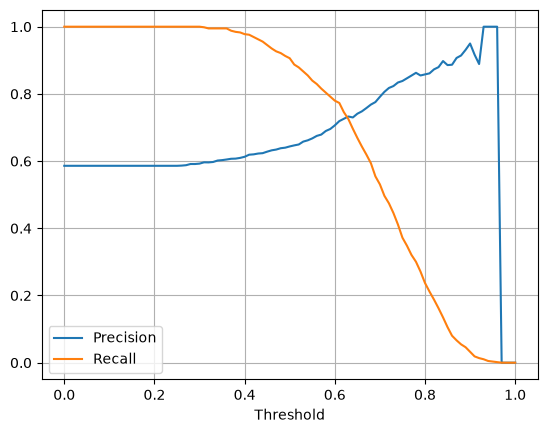

In [12]:
# Q3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0, 1.01, 0.01)

scores = []

for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)

    precision = precision_score(y_val, y_pred_binary, zero_division=0)
    recall = recall_score(y_val, y_pred_binary, zero_division=0)

    scores.append({
        'threshold': t,
        'precision': precision,
        'recall': recall
    })

df_scores = pd.DataFrame(scores)

plt.plot(df_scores['threshold'], df_scores['precision'], label='Precision')
plt.plot(df_scores['threshold'], df_scores['recall'], label='Recall')
plt.xlabel('Threshold')
plt.legend()
plt.grid()
plt.show()

In [13]:
# Q4
df_scores['f1'] = (
    2 * df_scores['precision'] * df_scores['recall']
    / (df_scores['precision'] + df_scores['recall'])
).fillna(0)

df_scores.sort_values('f1', ascending=False).head()

df_scores.loc[df_scores['f1'].idxmax()]

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64

In [14]:
# Q5
import numpy as np
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train['converted'].values
    y_val = df_val['converted'].values

    X_train_dict = df_train.drop(columns=['converted']).to_dict(orient='records')
    X_val_dict = df_val.drop(columns=['converted']).to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(X_train_dict)
    X_val = dv.transform(X_val_dict)

    model = LogisticRegression(
        solver='liblinear', C=1.0, max_iter=1000
    )
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    scores.append(roc_auc_score(y_val, y_pred))

print('Scores:', scores)
print('Mean:', np.mean(scores))
print('Standard deviation:', np.std(scores))

Scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Mean: 0.7317269710972524
Standard deviation: 0.006853233151022138


In [15]:
# Q6
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import numpy as np

for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train['converted'].values
        y_val = df_val['converted'].values

        train_dicts = df_train.drop(columns=['converted']).to_dict(orient='records')
        val_dicts = df_val.drop(columns=['converted']).to_dict(orient='records')

        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(train_dicts)
        X_val = dv.transform(val_dicts)

        model = LogisticRegression(
            solver='liblinear', C=C, max_iter=1000
        )
        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:, 1]
        scores.append(roc_auc_score(y_val, y_pred))

    print(f'C={C}: mean={np.mean(scores):.3f}, std={np.std(scores):.3f}')

C=1e-06: mean=0.617, std=0.019
C=0.001: mean=0.749, std=0.010
C=1: mean=0.732, std=0.007
